# Data Challenge: PISA 2025 en Argentina

*Introducción al Análisis de Datos, UTN-FRH. Trabajo individual.*

## 1. Introducción

### El dataset
PISA (Programa para la Evaluación Internacional de Estudiantes) es la evaluación que organiza la OCDE cada tres años para medir qué saben hacer los estudiantes de 15 años en Matemática, Lectura y Ciencias. En la edición 2025 el dominio principal fue Ciencias. Además de la prueba, cada estudiante responde un cuestionario sobre su hogar, su escuela, sus clases y su uso de tecnología, y el director de cada escuela completa otro cuestionario sobre la institución.

Trabajo con los archivos públicos de PISA 2025 (Public Use Files), filtrados para Argentina: **11.092 estudiantes de 412 escuelas**.

- Fuente: OCDE, *PISA 2025 Database*, https://www.oecd.org/en/data/datasets/pisa-2025-database.html
- Documentación consultada: el codebook 2025 (`PISA2025_Codebook.xlsx`) y los cuestionarios de estudiantes y escuelas.

Los archivos originales están en formato SPSS (`.sav`) y el de estudiantes pesa más de 2 GB, con datos de todos los países. Por eso escribí un script aparte, `preparar_datos.py`, que lee ese archivo en pedazos, se queda con Argentina y con las variables que uso, y guarda dos archivos livianos: `pisa2025_arg_estudiantes.csv` y `pisa2025_arg_escuelas.csv`. Este notebook trabaja solo con esos dos CSV.

### Contexto y motivación
En las escuelas se repite una preocupación: estudiantes distraídos por el celular, muchas horas frente a pantallas fuera del horario escolar y, desde hace poco, el uso de chatbots de inteligencia artificial para hacer las tareas. El cuestionario de PISA 2025 incluye preguntas sobre los tres temas, entre ellas una que consulta directamente con qué frecuencia los estudiantes se distraen con dispositivos digitales en las clases de ciencias.

Este análisis se vincula con MaestrIA, un asistente de IA pensado para ayudar a los docentes a diseñar y corregir evaluaciones escritas y a dar devoluciones, siempre con el docente revisando y decidiendo. Saber qué factores acompañan a un mejor o peor desempeño ayuda a pensar en qué parte del proceso puede servir una herramienta así y en qué parte no.

### Preguntas guía
1. **¿Qué factores del entorno de aprendizaje se asocian con mayores diferencias de desempeño en Matemática, Lectura y Ciencias entre los estudiantes argentinos de 15 años: la distracción por dispositivos en clase, el tiempo de pantallas por ocio, el clima disciplinario o el nivel socioeconómico?**
2. **¿Con qué frecuencia usan los estudiantes los chatbots de IA para la escuela (resumir, investigar, redactar, aprender) y cómo se relaciona cada uso con su desempeño?**

### Alcance
- La población son estudiantes de 15 años escolarizados. Las conclusiones valen para ese grupo, no para todo el sistema educativo.
- Los datos son de un solo momento y surgen de una encuesta, así que permiten describir **asociaciones**, no establecer causas. Si los estudiantes que se distraen más rinden menos, eso no prueba que la distracción sea la causa.
- Para los puntajes uso el primer valor plausible de cada materia (`PV1MATH`, `PV1READ`, `PV1SCIE`) y no aplico los pesos muestrales de PISA. En las conclusiones detallo qué implica esta simplificación.

## 2. Exploración inicial

Primero se importan las librerías y se cargan los CSV preparados a partir de los archivos públicos de PISA 2025.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo de gráficos usado en la cursada
plt.style.use('seaborn-v0_8')
sns.set_palette('muted')

Para ejecutar el notebook en Google Colab, primero hay que subir los datos desde el panel lateral, como se hizo en clase:

1. Abrir el panel de archivos (ícono de carpeta, a la izquierda).
2. Crear una carpeta llamada `data` (clic derecho > Nueva carpeta).
3. Subir dentro de esa carpeta los tres CSV: `pisa2025_arg_estudiantes.csv`, `pisa2025_arg_escuelas.csv` y `pisa2025_arg_codigos_faltantes.csv`.

Así la ruta `data/` funciona igual en Colab y en una computadora local.

In [2]:
# Los CSV están en la carpeta data/ (en Colab, la que se crea en el panel lateral)
carpeta = 'data/'

estudiantes = pd.read_csv(carpeta + 'pisa2025_arg_estudiantes.csv')
escuelas = pd.read_csv(carpeta + 'pisa2025_arg_escuelas.csv')

### 2.1 Dimensiones y primeras filas

In [3]:
print('Estudiantes:', estudiantes.shape)
print('Escuelas:', escuelas.shape)

Estudiantes: (11092, 59)
Escuelas: (412, 5)


In [4]:
estudiantes.head()

,CNT,CNTSCHID,CNTSTUID,MALE,ST250Q04JA,ST097Q01TA,ST097Q02TA,ST097Q03TA,ST097Q04TA,ST097Q05TA,...,PV4READ,PV5READ,PV6READ,PV7READ,PV8READ,PV9READ,PV10READ,cuestionario_administrado,cuestionario_tic_administrado,ia_escuela_codigo_original
0,ARG,3200001,3200001,1.0,1.0,3.0,3.0,3.0,4.0,2.0,...,501.655085,510.901170,398.557368,524.778848,502.435195,458.612719,460.692049,1,1,99.0
1,ARG,3200001,3200002,0.0,1.0,3.0,2.0,3.0,2.0,NaN,...,308.859792,275.441596,392.713512,353.080611,382.271740,361.252432,275.626428,1,1,99.0
2,ARG,3200001,3200003,0.0,1.0,3.0,2.0,3.0,3.0,3.0,...,488.033277,477.265384,442.493769,478.840866,463.107629,494.160499,495.065453,1,1,99.0
3,ARG,3200001,3200004,0.0,1.0,2.0,3.0,1.0,3.0,1.0,...,237.544934,260.356522,241.737797,312.684701,342.132885,335.226210,366.802136,1,1,99.0
4,ARG,3200001,3200005,1.0,1.0,2.0,2.0,2.0,3.0,3.0,...,341.232403,348.349695,357.292023,351.330295,361.739706,336.601204,370.851343,1,1,2.0


La tabla de estudiantes tiene 11.092 filas, una por estudiante, y 59 columnas. La de escuelas tiene 412 filas, una por escuela, y se vincula con la anterior por el identificador `CNTSCHID`. En promedio hay unos 27 estudiantes por escuela.

In [5]:
estudiantes.info()

<class 'pandas.DataFrame'>
RangeIndex: 11092 entries, 0 to 11091
Data columns (total 59 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CNT                            11092 non-null  str    
 1   CNTSCHID                       11092 non-null  int64  
 2   CNTSTUID                       11092 non-null  int64  
 3   MALE                           11092 non-null  float64
 4   ST250Q04JA                     10055 non-null  float64
 5   ST097Q01TA                     9749 non-null   float64
 6   ST097Q02TA                     9599 non-null   float64
 7   ST097Q03TA                     9572 non-null   float64
 8   ST097Q04TA                     9456 non-null   float64
 9   ST097Q05TA                     9433 non-null   float64
 10  ST097Q06DA                     9437 non-null   float64
 11  ST326Q04JA                     7650 non-null   float64
 12  ST326Q05JA                     7647 non-null   float64
 1

Casi todas las columnas son `float64`, incluso las preguntas del cuestionario, que en realidad son categorías (1, 2, 3...). Pandas las guarda como decimales porque tienen valores vacíos. Los identificadores (`CNTSCHID`, `CNTSTUID`) son enteros y `CNT` es texto.

La cantidad de valores no nulos varía mucho entre columnas. Los puntajes están completos (11.092), mientras que las preguntas del cuestionario tienen entre 5.600 y 10.200 respuestas. Eso se analiza en la sección de limpieza.

In [6]:
escuelas.info()

<class 'pandas.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CNT         412 non-null    str    
 1   CNTSCHID    412 non-null    int64  
 2   SC001Q01TA  352 non-null    float64
 3   SC190Q02JA  349 non-null    float64
 4   PRIVATESCH  412 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 16.2 KB


En escuelas, el tipo de gestión (`PRIVATESCH`, que después llamo `gestion`) está completo porque surge del diseño de la muestra. El tamaño de la localidad y la prohibición de celulares vienen del cuestionario del director y tienen 60 y 63 escuelas sin respuesta, respectivamente.

### 2.2 Qué significa cada variable
Los nombres originales de las columnas son códigos de PISA (por ejemplo, `ST250Q04JA`), que no dicen nada por sí solos. La tabla resume las variables que uso, con su código original, el nombre más descriptivo que les doy en la sección 2.3, su significado y su escala. Los significados y escalas salen del codebook 2025.

| Código PISA | Nombre en el notebook | Significado | Escala |
|---|---|---|---|
| `CNT` | `pais` | País (todas las filas son ARG) | texto |
| `CNTSCHID`, `CNTSTUID` | `id_escuela`, `id_estudiante` | Identificador de escuela y de estudiante | número |
| `MALE` | `genero` | Género según los datos de muestreo | 1 = varón, 0 = mujer |
| `REPEAT` | `repitio` | Repitió al menos un año | 1 = sí, 0 = no |
| `W_FSTUWT` | `peso_final` | Peso muestral del estudiante (cuántos estudiantes de la población representa) | número positivo |
| (creada en `preparar_datos.py`) | `cuestionario_administrado` | El estudiante recibió el cuestionario de contexto | 1 = sí, 0 = no |
| (creada en `preparar_datos.py`) | `cuestionario_tic_administrado` | El estudiante recibió el cuestionario TIC, que es aparte | 1 = sí, 0 = no |
| (creada en `preparar_datos.py`) | `ia_escuela_codigo_original` | Valor original de `IC170Q10DA`, con los códigos de faltante conservados | 1 a 6, 96, 97, 99 |
| `PV1MATH` … `PV10MATH` | `pv1_matematica` … `pv10_matematica` | Valores plausibles del puntaje en Matemática (igual para Lectura y Ciencias: `pv1_lectura`, `pv1_ciencias`...) | escala PISA |
| `ESCS` | `indice_socioeconomico` | Índice de nivel económico, social y cultural del hogar | continuo; 0 = promedio OCDE |
| `ST097Q01TA` | `clima_no_escuchan` | En clase de ciencias, los estudiantes no escuchan al docente | 1 = todas las clases … 4 = nunca o casi nunca |
| `ST097Q02TA` | `clima_ruido` | Hay ruido y desorden | ídem |
| `ST097Q03TA` | `clima_esperan_silencio` | El docente tiene que esperar mucho a que se calmen | ídem |
| `ST097Q04TA` | `clima_no_trabajan` | Los estudiantes no pueden trabajar bien | ídem |
| `ST097Q05TA` | `clima_tardan_empezar` | Tardan mucho en empezar a trabajar | ídem |
| `ST097Q06DA` | `distraccion_dispositivos` | Los estudiantes se distraen usando dispositivos digitales (celulares, sitios, apps) | ídem |
| `DISCLISCI` | `indice_clima_disciplinario` | Índice de clima disciplinario en ciencias (más alto = mejor clima) | continuo |
| `ST326Q04JA` | `ocio_horas_escuela` | Horas diarias de uso de dispositivos por ocio en la escuela | 1 = nada, 2 = hasta 1 h … 9 = más de 7 h |
| `ST326Q05JA` | `ocio_horas_dias_habiles` | Ídem, antes y después de la escuela | ídem |
| `ST326Q06JA` | `ocio_horas_finde` | Ídem, los fines de semana | ídem |
| `IC177Q02JA` | `redes_horas_dia_habil` | Tiempo en redes sociales en un día de semana | 1 = nada, 2 = menos de 1 h, 3 = 1 a 3 h, 4 = 3 a 5 h, 5 = 5 a 7 h, 6 = más de 7 h |
| `ST322Q06JA` | `presion_responder_en_clase` | Se siente presionado a estar en línea y responder mensajes durante la clase | 1 = nunca … 5 = siempre; 6 = no aplica |
| `ST250Q04JA` | `celular_propio` | Tiene celular propio con internet | 1 = sí, 2 = no |
| `ST438Q01DA` | `ia_resumir` | Usa chatbots de IA para la escuela para resumir un texto | 1 = nunca … 5 = todos los días |
| `ST438Q02DA` | `ia_investigar` | … para investigar un tema nuevo | ídem |
| `ST438Q03DA` | `ia_redactar` | … para redactar trabajos escritos | ídem |
| `ST438Q04DA` | `ia_aprender` | … para ayudarse a aprender | ídem |
| `AIUSESCH` | `indice_uso_ia` | Índice de uso de IA en la escuela | continuo |
| `IC170Q10DA` | `ia_frecuencia_escuela` | Frecuencia de uso de herramientas de IA en la escuela | 1 = nunca … 5 = varias veces por día; 6 = no disponible |
| `PRIVATESCH` (escuelas) | `gestion` | Gestión de la escuela | 1 = pública, 2 = privada |
| `SC001Q01TA` (escuelas) | `tamanio_localidad` | Tamaño de la localidad | 1 = rural (menos de 3.000 hab.) … 6 = más de 10 millones |
| `SC190Q02JA` (escuelas) | `prohibe_celulares` | No se permite el uso de celulares en la escuela | 1 = sí, 2 = no |

Las preguntas del cuestionario son categorías guardadas como números. Hay que tener cuidado con el orden: en las preguntas de clima y distracción, un número más bajo indica una situación **más frecuente** (1 = en todas las clases).

Algunas de estas variables no entran en ninguna comparación: solo forman parte de la lista de preguntas con la que, en 3.4, identifico a los estudiantes sin ninguna respuesta. Son los cinco ítems `clima_*`, `ocio_horas_escuela`, `ocio_horas_finde`, `redes_horas_dia_habil`, `presion_responder_en_clase` y `celular_propio`. Los ítems `clima_*` y `celular_propio` además se recodifican en 4.1, pero el análisis de clima usa el índice `indice_clima_disciplinario`.

### 2.3 Nombres más descriptivos
Renombro las columnas con `.rename()` usando un diccionario. Para los 30 valores plausibles armo los nombres con un ciclo `for`, en lugar de escribirlos uno por uno. Los CSV conservan los códigos originales, así que cualquier columna se puede rastrear en el codebook con la tabla anterior.

In [7]:
nombres_estudiantes = {
    'CNT': 'pais',
    'CNTSCHID': 'id_escuela',
    'CNTSTUID': 'id_estudiante',
    'MALE': 'genero',
    'REPEAT': 'repitio',
    'ESCS': 'indice_socioeconomico',
    'W_FSTUWT': 'peso_final',
    'ST097Q01TA': 'clima_no_escuchan',
    'ST097Q02TA': 'clima_ruido',
    'ST097Q03TA': 'clima_esperan_silencio',
    'ST097Q04TA': 'clima_no_trabajan',
    'ST097Q05TA': 'clima_tardan_empezar',
    'ST097Q06DA': 'distraccion_dispositivos',
    'DISCLISCI': 'indice_clima_disciplinario',
    'ST326Q04JA': 'ocio_horas_escuela',
    'ST326Q05JA': 'ocio_horas_dias_habiles',
    'ST326Q06JA': 'ocio_horas_finde',
    'IC177Q02JA': 'redes_horas_dia_habil',
    'ST322Q06JA': 'presion_responder_en_clase',
    'ST250Q04JA': 'celular_propio',
    'ST438Q01DA': 'ia_resumir',
    'ST438Q02DA': 'ia_investigar',
    'ST438Q03DA': 'ia_redactar',
    'ST438Q04DA': 'ia_aprender',
    'AIUSESCH': 'indice_uso_ia',
    'IC170Q10DA': 'ia_frecuencia_escuela',
}

# Valores plausibles: PV1MATH -> pv1_matematica, PV2MATH -> pv2_matematica, etc.
materias = {'MATH': 'matematica', 'READ': 'lectura', 'SCIE': 'ciencias'}
for codigo, materia in materias.items():
    for i in range(1, 11):
        nombres_estudiantes[f'PV{i}{codigo}'] = f'pv{i}_{materia}'

estudiantes = estudiantes.rename(columns=nombres_estudiantes)

escuelas = escuelas.rename(columns={
    'CNT': 'pais',
    'CNTSCHID': 'id_escuela',
    'PRIVATESCH': 'gestion',
    'SC001Q01TA': 'tamanio_localidad',
    'SC190Q02JA': 'prohibe_celulares',
})

print(estudiantes.columns.tolist())
print(escuelas.columns.tolist())

['pais', 'id_escuela', 'id_estudiante', 'genero', 'celular_propio', 'clima_no_escuchan', 'clima_ruido', 'clima_esperan_silencio', 'clima_no_trabajan', 'clima_tardan_empezar', 'distraccion_dispositivos', 'ocio_horas_escuela', 'ocio_horas_dias_habiles', 'ocio_horas_finde', 'ia_resumir', 'ia_investigar', 'ia_redactar', 'ia_aprender', 'presion_responder_en_clase', 'ia_frecuencia_escuela', 'redes_horas_dia_habil', 'indice_clima_disciplinario', 'indice_uso_ia', 'indice_socioeconomico', 'repitio', 'peso_final', 'pv1_ciencias', 'pv2_ciencias', 'pv3_ciencias', 'pv4_ciencias', 'pv5_ciencias', 'pv6_ciencias', 'pv7_ciencias', 'pv8_ciencias', 'pv9_ciencias', 'pv10_ciencias', 'pv1_matematica', 'pv2_matematica', 'pv3_matematica', 'pv4_matematica', 'pv5_matematica', 'pv6_matematica', 'pv7_matematica', 'pv8_matematica', 'pv9_matematica', 'pv10_matematica', 'pv1_lectura', 'pv2_lectura', 'pv3_lectura', 'pv4_lectura', 'pv5_lectura', 'pv6_lectura', 'pv7_lectura', 'pv8_lectura', 'pv9_lectura', 'pv10_lectura

### 2.4 Estadísticas descriptivas
Primero, los puntajes (primer valor plausible de cada materia) y los tres índices continuos.

In [8]:
columnas_numericas = ['pv1_matematica', 'pv1_lectura', 'pv1_ciencias',
                      'indice_socioeconomico', 'indice_clima_disciplinario', 'indice_uso_ia']
estudiantes[columnas_numericas].describe().round(2)

,pv1_matematica,pv1_lectura,pv1_ciencias,indice_socioeconomico,indice_clima_disciplinario,indice_uso_ia
count,11092.00,11092.00,11092.00,9808.00,9616.00,7728.00
mean,383.63,402.70,413.38,-0.50,-0.38,0.26
std,81.39,92.04,92.57,1.05,0.98,1.01
min,118.61,77.51,114.31,-4.09,-2.62,-1.58
25%,325.27,336.33,344.91,-1.29,-0.99,-0.34
50%,378.98,400.14,409.90,-0.55,-0.41,0.14
75%,438.35,466.83,478.83,0.35,0.26,0.84
max,707.25,741.06,767.41,3.26,1.99,2.34


Los promedios son 383,6 puntos en Matemática, 402,7 en Lectura y 413,4 en Ciencias. Como referencia, la escala de PISA se construyó para que el promedio de los países de la OCDE rondara los 500 puntos. La dispersión es grande: en Matemática, el 25 % de los estudiantes con menor puntaje queda por debajo de 325 puntos y el 25 % con mayor puntaje supera los 438.

El índice socioeconómico (`indice_socioeconomico`) tiene una media de −0,50: en promedio, los hogares de estos estudiantes están medio desvío por debajo del promedio de la OCDE. El índice de clima disciplinario también es negativo en promedio (−0,38).

#### Comparación con los promedios oficiales
Los promedios oficiales de Argentina en PISA 2025 son 367 puntos en Matemática, 389 en Lectura y 393 en Ciencias, más bajos que los de la tabla anterior. La diferencia está en los pesos muestrales: la OCDE calcula sus promedios ponderando a cada estudiante por `peso_final`, que indica cuántos estudiantes de la población representa. La celda siguiente compara el promedio simple con el ponderado.

In [9]:
for materia in ['matematica', 'lectura', 'ciencias']:
    columna = 'pv1_' + materia
    simple = estudiantes[columna].mean()
    # Promedio ponderado: suma de puntaje x peso, dividida por la suma de los pesos
    ponderado = (estudiantes[columna] * estudiantes['peso_final']).sum() / estudiantes['peso_final'].sum()
    print(materia, '-> sin ponderar:', round(simple, 1), '| ponderado:', round(ponderado, 1))

matematica -> sin ponderar: 383.6 | ponderado: 367.0
lectura -> sin ponderar: 402.7 | ponderado: 388.7
ciencias -> sin ponderar: 413.4 | ponderado: 392.8


Con los pesos, el promedio de PV1 da 367,0 en Matemática, 388,7 en Lectura y 392,8 en Ciencias, prácticamente iguales a los oficiales. Sin pesos, los promedios quedan 16,6, 13,7 y 20,4 puntos por encima de los oficiales (y 16,6, 14,0 y 20,6 puntos por encima del ponderado calculado acá).

La razón es que la muestra argentina no es proporcional: algunas jurisdicciones, que en el codebook figuran como regiones separadas, tienen muchos más estudiantes en la muestra de los que les corresponden en la población. Lo verifiqué en el archivo original al preparar los datos; la variable de región no está en los CSV, así que esta tabla no se recalcula en el notebook:

| Región | % de la muestra | % de la población (según los pesos) | PV1 Matemática |
|---|---|---|---|
| CABA | 20,5 | 5,8 | 419,6 |
| Córdoba | 20,2 | 8,4 | 395,9 |
| Mendoza | 18,9 | 4,5 | 375,0 |
| Resto del país | 40,4 | 81,2 | 363,3 |

Las tres jurisdicciones sobrerrepresentadas tienen promedios más altos que el resto del país, y eso sube el promedio simple. En este trabajo uso promedios sin ponderar, con las técnicas vistas en clase, así que los niveles absolutos no son los oficiales. Las comparaciones entre grupos siguen siendo informativas, aunque también pueden estar influidas por la composición de la muestra. Lo retomo en las limitaciones.

### 2.5 Primeras frecuencias
Con qué frecuencia los estudiantes dicen que en sus clases de ciencias hay distracción por dispositivos (porcentaje de los que respondieron):

In [10]:
# 1 = en todas las clases, 2 = en la mayoría, 3 = en algunas, 4 = nunca o casi nunca
# .loc ordena las opciones según la escala
estudiantes['distraccion_dispositivos'].value_counts(normalize=True).mul(100).round(1).loc[[1, 2, 3, 4]]

distraccion_dispositivos
1.0    28.6
2.0    24.6
3.0    27.3
4.0    19.5
Name: proportion, dtype: float64

El 28,6 % dice que hay distracción con dispositivos en todas las clases de ciencias y el 24,6 % en la mayoría. En total, el 53,2 % la percibe en todas o en la mayoría de las clases. Solo el 19,5 % responde que nunca o casi nunca pasa.

In [11]:
# Uso de chatbots de IA 'para ayudarme a aprender'
# 1 = nunca, 2 = 1 o 2 veces al año, 3 = 1 o 2 veces al mes, 4 = 1 o 2 veces por semana, 5 = todos los días
estudiantes['ia_aprender'].value_counts(normalize=True).mul(100).round(1).loc[[1, 2, 3, 4, 5]]

ia_aprender
1.0    15.4
2.0    13.5
3.0    18.6
4.0    25.8
5.0    26.8
Name: proportion, dtype: float64

El uso de IA está muy extendido: el 52,6 % de los que respondieron usa chatbots para ayudarse a aprender al menos una vez por semana, y solo el 15,4 % dice que nunca lo hace.

In [12]:
print(escuelas['gestion'].value_counts())
print(escuelas['prohibe_celulares'].value_counts())
print('Sin dato:', escuelas['prohibe_celulares'].isna().sum())

gestion
1.0    277
2.0    135
Name: count, dtype: int64
prohibe_celulares
2.0    222
1.0    127
Name: count, dtype: int64
Sin dato: 63


De las 412 escuelas, 277 son de gestión pública y 135 de gestión privada. Entre las que respondieron, 127 no permiten el uso de celulares y 222 sí lo permiten; 63 no informaron.

## 3. Limpieza de datos

En esta sección reviso duplicados, columnas que no aportan, tipos de datos, códigos que no son respuestas válidas y valores faltantes. Para cada caso explico qué decidí y por qué.

### 3.1 Duplicados
Busco filas repetidas completas y, además, identificadores repetidos: un mismo estudiante no debería aparecer dos veces, ni una escuela en la tabla de escuelas.

In [13]:
print('Filas duplicadas en estudiantes:', estudiantes.duplicated().sum())
print('IDs de estudiante repetidos:', estudiantes['id_estudiante'].duplicated().sum())
print('IDs de escuela repetidos en escuelas:', escuelas['id_escuela'].duplicated().sum())

Filas duplicadas en estudiantes: 0
IDs de estudiante repetidos: 0
IDs de escuela repetidos en escuelas: 0


In [14]:
# Aunque no hay duplicados, dejo el paso explícito para que la limpieza siga siendo válida si cambian los datos
estudiantes = estudiantes.drop_duplicates()
escuelas = escuelas.drop_duplicates(subset='id_escuela')
print(estudiantes.shape, escuelas.shape)

(11092, 59) (412, 5)


No hay filas ni identificadores repetidos. Era esperable, porque la OCDE publica estas bases ya depuradas, pero conviene comprobarlo antes de unir las dos tablas: un ID de escuela repetido duplicaría a todos sus estudiantes en la unión.

### 3.2 Columnas que no aportan y tipos de datos
La columna `pais` vino del filtro por Argentina, así que debería tener un único valor.

In [15]:
print(estudiantes['pais'].unique())
print(escuelas['pais'].unique())

<StringArray>
['ARG']
Length: 1, dtype: str
<StringArray>
['ARG']
Length: 1, dtype: str


In [16]:
# Columna constante: no aporta información
estudiantes = estudiantes.drop(columns=['pais'])
escuelas = escuelas.drop(columns=['pais'])

# genero no tiene faltantes y solo toma 0 o 1, convierto el tipo de dato a entero
estudiantes['genero'] = estudiantes['genero'].astype(int)
estudiantes['genero'].value_counts()

genero
0    5588
1    5504
Name: count, dtype: int64

Eliminé `pais` en las dos tablas porque todas las filas dicen ARG. Los identificadores ya eran enteros. Las demás preguntas del cuestionario siguen como `float64` porque tienen valores vacíos; en la sección 4 las convierto en categorías con texto.

### 3.3 Opciones que no son frecuencias
Dos preguntas tienen una sexta opción que no forma parte de la escala de frecuencia:

- `presion_responder_en_clase`: el 6 es "no aplica". El cuestionario de estudiantes indica, en el enunciado de la pregunta ST322, que la elija quien no tiene o no usa un dispositivo digital (página 61 del documento, 62 del PDF).
- `ia_frecuencia_escuela`: el 6 es "este recurso no está disponible para mí en la escuela", según la etiqueta de la variable IC170Q10DA en el codebook 2025 (hoja STU). Esta pregunta es del cuestionario TIC, que no está en el PDF del cuestionario principal.

En el codebook 2025 las dos figuran como opciones de respuesta, con su propia etiqueta. No son faltantes del sistema: en estas preguntas, ese tipo de faltante tiene el código 96 y afecta a 19 estudiantes en cada una (ver la tabla de 3.4), mientras que la opción 6 la eligieron cientos.

El 6 dice algo, pero no puede ordenarse junto con las demás opciones: si queda como número, en un promedio o en un orden aparecería por encima de "siempre". Por eso primero guardo esa información en dos columnas indicadoras (1 = eligió la opción 6, 0 = eligió otra, vacío = no respondió) y después reemplazo el 6 por un valor vacío en la pregunta original.

In [17]:
# Indicadores: se crean antes de borrar el 6
estudiantes.loc[estudiantes['presion_responder_en_clase'].notna(), 'presion_no_aplica'] = 0
estudiantes.loc[estudiantes['presion_responder_en_clase'] == 6, 'presion_no_aplica'] = 1
estudiantes.loc[estudiantes['ia_frecuencia_escuela'].notna(), 'ia_no_disponible_escuela'] = 0
estudiantes.loc[estudiantes['ia_frecuencia_escuela'] == 6, 'ia_no_disponible_escuela'] = 1

print(estudiantes['presion_no_aplica'].value_counts())
print(estudiantes['ia_no_disponible_escuela'].value_counts())

# En las preguntas originales, el 6 pasa a vacío
estudiantes.loc[estudiantes['presion_responder_en_clase'] == 6, 'presion_responder_en_clase'] = np.nan
estudiantes.loc[estudiantes['ia_frecuencia_escuela'] == 6, 'ia_frecuencia_escuela'] = np.nan

presion_no_aplica
0.0    6970
1.0     443
Name: count, dtype: int64
ia_no_disponible_escuela
0.0    5233
1.0     400
Name: count, dtype: int64


Hay 443 estudiantes que eligieron "no aplica" en la pregunta sobre la presión por responder mensajes y 400 que indicaron que en su escuela no tienen herramientas de IA disponibles. La columna `ia_no_disponible_escuela` se usa en la sección 4 para comparar la disponibilidad de IA según el tipo de gestión de la escuela.

### 3.4 Valores faltantes
Porcentaje de valores vacíos por columna, de mayor a menor (solo las columnas que tienen alguno):

In [18]:
faltantes = estudiantes.isna().mean().mul(100).round(1).sort_values(ascending=False)
faltantes[faltantes > 0]

ia_frecuencia_escuela         52.8
ia_no_disponible_escuela      49.2
redes_horas_dia_habil         45.4
presion_responder_en_clase    37.2
presion_no_aplica             33.2
ocio_horas_dias_habiles       31.1
ocio_horas_finde              31.1
ocio_horas_escuela            31.0
ia_aprender                   31.0
ia_redactar                   30.8
indice_uso_ia                 30.3
ia_investigar                 30.0
ia_resumir                    29.2
clima_tardan_empezar          15.0
distraccion_dispositivos      14.9
clima_no_trabajan             14.7
clima_esperan_silencio        13.7
clima_ruido                   13.5
indice_clima_disciplinario    13.3
clima_no_escuchan             12.1
indice_socioeconomico         11.6
celular_propio                 9.3
repitio                        8.4
dtype: float64

Los puntajes no tienen faltantes. Las preguntas sobre pantallas e inteligencia artificial rondan el 30 % de vacíos, y dos superan bastante ese valor: el uso de IA en la escuela (52,8 %, que incluye los 400 casos de "no disponible") y el tiempo en redes sociales (45,4 %). Las preguntas de clima en clase tienen entre 12 % y 15 %, y el índice socioeconómico 11,6 %. Las dos columnas indicadoras creadas en 3.3 heredan los vacíos de su pregunta original.

#### Dos tipos de faltante
PISA no usa un único código para los datos que faltan. En el archivo original, cada pregunta distingue, entre otros:

| Código (preguntas de 1 dígito / de 2 dígitos) | Significado |
|---|---|
| 7 / 97 | No administrado: la pregunta no se le presentó al estudiante |
| 9 / 99 | Sin respuesta: la pregunta se presentó y quedó sin contestar |
| 6 / 96 | Perdido del sistema |

Al leer el archivo, `pyreadstat` convierte todos estos códigos en valores vacíos, y la diferencia se pierde. Por eso `preparar_datos.py` la conserva de dos formas: la columna `cuestionario_administrado` y una tabla con la cantidad de cada código en algunas preguntas, ordenadas como aparecen en el cuestionario.

In [19]:
codigos_faltantes = pd.read_csv(carpeta + 'pisa2025_arg_codigos_faltantes.csv')
codigos_faltantes

,variable,cuestionario,pagina_cuestionario,no_administrado,sin_respuesta,perdido_sistema
0,ST250Q04JA,principal,8.0,526,508,3
1,REPEAT,principal,27.0,526,397,6
2,ST097Q01TA,principal,34.0,526,809,8
3,ST097Q06DA,principal,34.0,526,1121,8
4,ST326Q05JA,principal,56.0,526,2896,23
5,ST438Q04DA,principal,61.0,526,2894,20
6,ST322Q06JA,principal,62.0,526,3134,19
7,IC170Q10DA,TIC,NaN,643,4797,19
8,IC177Q02JA,TIC,NaN,643,4376,18


Los 526 estudiantes con la pregunta no administrada son los mismos en todo el cuestionario principal: no recibieron el cuestionario de contexto, aunque sí tienen puntajes de la prueba. En el cuestionario TIC, que es aparte, los no administrados suben a 643.

La falta de respuesta (código 9/99) es otra cosa. En el cuestionario principal tiene 508 y 397 casos en las dos primeras preguntas de la tabla (páginas 8 y 27 del PDF). Pasa a 809 y 1.121 en la página 34 y a entre 2.894 y 3.134 desde la página 56. En general aumenta hacia el final del cuestionario, aunque no en todos los pasos: la pregunta de la página 27 tiene menos casos que la de la página 8. Las dos preguntas del cuestionario TIC son las que más casos sin respuesta tienen (4.376 y 4.797). Con estos datos no es posible saber a qué se debe. Los perdidos del sistema son pocos, entre 3 y 23 por pregunta.

Los estudiantes que recibieron el cuestionario principal pero no el TIC se identifican con las dos columnas de administración:

In [20]:
sin_tic = estudiantes[(estudiantes['cuestionario_administrado'] == 1) & (estudiantes['cuestionario_tic_administrado'] == 0)]
print('Estudiantes:', len(sin_tic))
print('PV1 Matemática promedio:', round(sin_tic['pv1_matematica'].mean(), 1))
print('Con respuesta en ia_aprender (cuestionario principal):', sin_tic['ia_aprender'].notna().sum())

Estudiantes: 117
PV1 Matemática promedio: 394.2
Con respuesta en ia_aprender (cuestionario principal): 66


Son 117 estudiantes, con un PV1 promedio de 394,2 puntos: no es un grupo de bajo desempeño. Quedan sin dato solo en las dos variables del cuestionario TIC (`ia_frecuencia_escuela` y `redes_horas_dia_habil`). Las preguntas sobre chatbots son del cuestionario principal, y 66 de estos estudiantes respondieron `ia_aprender`.

En `ia_frecuencia_escuela` hay tres razones distintas para que el valor esté vacío, además de la opción 6 que vacié en 3.3. La columna con el código original permite separarlas:

In [21]:
# Códigos originales de las filas que quedaron vacías en ia_frecuencia_escuela
# 6 = no disponible, 96 = perdido del sistema, 97 = no administrado, 99 = sin respuesta
vacias = estudiantes['ia_frecuencia_escuela'].isna()
estudiantes.loc[vacias, 'ia_escuela_codigo_original'].value_counts()

ia_escuela_codigo_original
99.0    4797
97.0     643
6.0      400
96.0      19
Name: count, dtype: int64

Sobre los 11.092 estudiantes, los vacíos de `ia_frecuencia_escuela` se reparten así: 4.797 por falta de respuesta, 643 porque el estudiante no recibió el cuestionario TIC y 19 perdidos del sistema. Los 400 casos con código 6 no son un faltante: son estudiantes que dicen que en su escuela no tienen herramientas de IA disponibles. En las comparaciones de la sección 4 los trato como un grupo propio ("No disponible"), separado de los que no tienen dato.

In [22]:
estudiantes['cuestionario_administrado'].value_counts()

cuestionario_administrado
1    10566
0      526
Name: count, dtype: int64

Ahora comparo el puntaje en Matemática según cómo quedó la pregunta sobre distracción: respondida, sin dato aunque el estudiante recibió el cuestionario, o no administrada.

In [23]:
# Columna auxiliar para separar los tres grupos
estudiantes['respuesta_distraccion'] = 'Respondió'
estudiantes.loc[estudiantes['distraccion_dispositivos'].isna(), 'respuesta_distraccion'] = 'Recibió el cuestionario, sin dato'
estudiantes.loc[estudiantes['cuestionario_administrado'] == 0, 'respuesta_distraccion'] = 'No recibió el cuestionario'

print(estudiantes.groupby('respuesta_distraccion')['pv1_matematica'].agg(['size', 'mean']).round(1))

# La columna auxiliar solo servía para esta comparación
estudiantes = estudiantes.drop(columns=['respuesta_distraccion'])

                                   size   mean
respuesta_distraccion                         
No recibió el cuestionario          526  352.6
Recibió el cuestionario, sin dato  1129  313.0
Respondió                          9437  393.8


Lo mismo para otras dos preguntas, pero solo entre quienes recibieron el cuestionario, para que la comparación refleje la falta de respuesta y no la falta de administración:

In [24]:
administrados = estudiantes[estudiantes['cuestionario_administrado'] == 1]
for columna in ['ia_aprender', 'indice_socioeconomico']:
    promedios = administrados.groupby(administrados[columna].isna())['pv1_matematica'].mean().round(1)
    print(columna, '-> respondió:', promedios[False], '| sin dato:', promedios[True])

ia_aprender -> respondió: 403.9 | sin dato: 336.1
indice_socioeconomico -> respondió: 389.7 | sin dato: 326.4


La falta de datos no se reparte de manera pareja. En la pregunta sobre distracción, quienes respondieron tienen en promedio 393,8 puntos; quienes recibieron el cuestionario pero no tienen dato, 313,0; y quienes no lo recibieron, 352,6. Entre los que recibieron el cuestionario, los que no respondieron sobre el uso de IA tienen 67,8 puntos menos que los que sí lo hicieron (336,1 contra 403,9), y los que no tienen índice socioeconómico, 63,3 puntos menos (326,4 contra 389,7).

La falta de respuesta, entonces, está asociada al desempeño, y tratarla como si fuera aleatoria sería arriesgado. Por eso descarto imputar: completar con la media o la mediana inventaría respuestas para un grupo que es distinto del resto y, en una pregunta con categorías ordenadas, pondría a miles de estudiantes en la opción del medio. Tomé dos decisiones:

1. Elimino solo a los estudiantes que no tienen ninguna respuesta en las preguntas que uso como factores, porque no aportan nada al análisis.
2. El resto de los faltantes queda como está. En cada comparación uso a quienes respondieron esa pregunta; pandas ya ignora los vacíos al calcular promedios, frecuencias y agrupaciones.

In [25]:
# Preguntas del cuestionario que uso como factores
factores = ['celular_propio', 'clima_no_escuchan', 'clima_ruido', 'clima_esperan_silencio',
            'clima_no_trabajan', 'clima_tardan_empezar', 'distraccion_dispositivos',
            'indice_clima_disciplinario', 'ocio_horas_escuela', 'ocio_horas_dias_habiles',
            'ocio_horas_finde', 'redes_horas_dia_habil', 'presion_responder_en_clase',
            'ia_resumir', 'ia_investigar', 'ia_redactar', 'ia_aprender', 'indice_uso_ia',
            'ia_frecuencia_escuela', 'indice_socioeconomico']

# True si el estudiante no tiene ninguna respuesta en esas columnas
sin_respuestas = estudiantes[factores].notna().sum(axis=1) == 0
print('Estudiantes sin ninguna respuesta en los factores:', sin_respuestas.sum())

# ¿Cuántos de ellos son los que no recibieron el cuestionario?
print(estudiantes.loc[sin_respuestas, 'cuestionario_administrado'].value_counts())

# Escuelas que se quedarían sin ningún estudiante
escuelas_que_quedan = estudiantes.loc[~sin_respuestas, 'id_escuela']
en_escuelas_perdidas = ~estudiantes['id_escuela'].isin(escuelas_que_quedan)
print('Escuelas antes:', estudiantes['id_escuela'].nunique(), '| después:', escuelas_que_quedan.nunique())
print('Estudiantes de esas escuelas, según si recibieron el cuestionario:')
print(estudiantes.loc[en_escuelas_perdidas, 'cuestionario_administrado'].value_counts())

promedio_antes = estudiantes['pv1_matematica'].mean()
estudiantes = estudiantes[~sin_respuestas]
promedio_despues = estudiantes['pv1_matematica'].mean()

print('Estudiantes que quedan:', len(estudiantes))
print('PV1 Matemática antes:', round(promedio_antes, 1), '| después:', round(promedio_despues, 1))

Estudiantes sin ninguna respuesta en los factores: 663
cuestionario_administrado
0    526
1    137
Name: count, dtype: int64
Escuelas antes: 412 | después: 405
Estudiantes de esas escuelas, según si recibieron el cuestionario:
cuestionario_administrado
0    160
1      1
Name: count, dtype: int64
Estudiantes que quedan: 10429
PV1 Matemática antes: 383.6 | después: 386.4


Se eliminaron 663 estudiantes, el 6,0 % del total. De ellos, 526 son justamente los que no recibieron el cuestionario; los otros 137 lo recibieron pero no respondieron ninguna de esas preguntas. Quedan 10.429 estudiantes. Con ellos se van 7 de las 412 escuelas, que quedan sin ningún estudiante: tenían 161 estudiantes y 160 no habían recibido el cuestionario.

Al eliminar estas filas, el promedio de PV1 en Matemática pasa de 383,6 a 386,4 puntos: sube 2,8 puntos. El efecto es chico, pero se suma al de los faltantes que quedan: en las tres preguntas revisadas, quienes respondieron tienen un desempeño mayor que quienes no lo hicieron (por ejemplo, 393,8 puntos en la pregunta sobre distracción). Lo retomo en las limitaciones. Los faltantes de la tabla de escuelas (60 escuelas sin tamaño de localidad y 63 sin dato sobre la prohibición de celulares, según el `info()` de 2.1) los completo en la sección 4 con la categoría "Sin dato", cuando esas columnas pasen a texto.

### 3.5 Dataset final
Repito las estadísticas descriptivas y la tabla de faltantes sobre los 10.429 estudiantes que quedan.

In [26]:
estudiantes[columnas_numericas].describe().round(2)

,pv1_matematica,pv1_lectura,pv1_ciencias,indice_socioeconomico,indice_clima_disciplinario,indice_uso_ia
count,10429.00,10429.00,10429.00,9808.00,9616.00,7728.00
mean,386.36,404.69,416.64,-0.50,-0.38,0.26
std,81.95,92.63,92.96,1.05,0.98,1.01
min,118.61,77.51,114.31,-4.09,-2.62,-1.58
25%,327.25,337.50,348.22,-1.29,-0.99,-0.34
50%,382.25,402.77,413.90,-0.55,-0.41,0.14
75%,441.61,469.47,482.54,0.35,0.26,0.84
max,707.25,741.06,767.41,3.26,1.99,2.34


In [27]:
faltantes_final = estudiantes.isna().mean().mul(100).round(1).sort_values(ascending=False)
faltantes_final[faltantes_final > 0]

ia_frecuencia_escuela         49.8
ia_no_disponible_escuela      46.0
redes_horas_dia_habil         41.9
presion_responder_en_clase    33.2
presion_no_aplica             28.9
ocio_horas_finde              26.8
ocio_horas_dias_habiles       26.7
ocio_horas_escuela            26.6
ia_aprender                   26.6
ia_redactar                   26.4
indice_uso_ia                 25.9
ia_investigar                 25.5
ia_resumir                    24.7
clima_tardan_empezar           9.6
distraccion_dispositivos       9.5
clima_no_trabajan              9.3
clima_esperan_silencio         8.2
clima_ruido                    8.0
indice_clima_disciplinario     7.8
clima_no_escuchan              6.5
indice_socioeconomico          6.0
celular_propio                 3.6
repitio                        2.8
dtype: float64

Respecto de 2.4, los promedios de los puntajes suben levemente (Matemática pasa de 383,63 a 386,36) porque los estudiantes eliminados tenían puntajes más bajos. Los índices no cambian, porque ninguno de los eliminados tenía índices calculados. Los faltantes bajan en todas las preguntas: la distracción pasa de 14,9 % a 9,5 % y el índice socioeconómico de 11,6 % a 6,0 %. Las variables del cuestionario TIC siguen siendo las más incompletas (49,8 % en `ia_frecuencia_escuela` y 41,9 % en `redes_horas_dia_habil`).

Las preguntas sobre chatbots de IA y el índice de uso de IA son las que sostienen la segunda pregunta guía. Para cada una, cuántos estudiantes respondieron, qué porcentaje representan y qué puntaje tienen frente a quienes no respondieron:

In [28]:
variables_ia = ['ia_resumir', 'ia_investigar', 'ia_redactar', 'ia_aprender', 'indice_uso_ia']
for columna in variables_ia:
    respondio = estudiantes[columna].notna()
    print(columna, '-> n:', respondio.sum(), '|', round(respondio.mean() * 100, 1), '%',
          '| PV1 respondió:', round(estudiantes.loc[respondio, 'pv1_matematica'].mean(), 1),
          '| sin dato:', round(estudiantes.loc[~respondio, 'pv1_matematica'].mean(), 1))

ia_resumir -> n: 7856 | 75.3 % | PV1 respondió: 401.8 | sin dato: 339.2
ia_investigar -> n: 7766 | 74.5 % | PV1 respondió: 402.8 | sin dato: 338.5
ia_redactar -> n: 7680 | 73.6 % | PV1 respondió: 403.5 | sin dato: 338.6
ia_aprender -> n: 7652 | 73.4 % | PV1 respondió: 403.9 | sin dato: 338.1
indice_uso_ia -> n: 7728 | 74.1 % | PV1 respondió: 403.5 | sin dato: 337.4


Entre 7.652 y 7.856 estudiantes respondieron cada pregunta sobre IA, entre el 73,4 % y el 75,3 % del dataset final. Quienes respondieron tienen entre 401,8 y 403,9 puntos en Matemática, contra 337,4 a 339,2 de quienes no lo hicieron: entre 62,6 y 66,1 puntos de diferencia. Todo lo que se concluya sobre el uso de IA vale, entonces, para una submuestra con mejor desempeño que el total. En cada comparación de IA indico el n de cada grupo.

## 4. Transformaciones

En esta sección pongo las escalas en el mismo sentido, uno los datos de estudiantes con los de sus escuelas, paso las categorías a texto y armo los terciles de nivel socioeconómico. Al final hago las primeras comparaciones, que sirven de control para la sección 5.

### 4.1 Escalas en el mismo sentido
En varias preguntas un número más bajo indica una situación más frecuente (1 = en todas las clases), y en otras al revés. Para que la lectura sea uniforme, recodifico con `.apply` las que van al revés, de modo que en todas un número más alto signifique "más" de lo que dice el nombre de la variable.

| Variable | Escala original | Escala nueva | Cambio |
|---|---|---|---|
| `clima_no_escuchan`, `clima_ruido`, `clima_esperan_silencio`, `clima_no_trabajan`, `clima_tardan_empezar` | 1 = todas las clases … 4 = nunca | 1 = nunca … 4 = todas las clases | invertida: `5 - x` |
| `distraccion_dispositivos` | 1 = todas las clases … 4 = nunca | 1 = nunca … 4 = todas las clases | invertida: `5 - x` |
| `celular_propio` | 1 = sí, 2 = no | 1 = sí, 0 = no | `2 - x` |
| `prohibe_celulares` (escuelas) | 1 = sí, 2 = no | 1 = sí, 0 = no | `2 - x` (en 4.2) |
| `ocio_horas_*`, `redes_horas_dia_habil` | 1 = nada … más horas | igual | sin cambio |
| `presion_responder_en_clase` | 1 = nunca … 5 = siempre | igual | sin cambio |
| `ia_resumir`, `ia_investigar`, `ia_redactar`, `ia_aprender`, `ia_frecuencia_escuela` | 1 = nunca … más frecuente | igual | sin cambio |
| `repitio`, `genero` | 0 / 1 | igual | sin cambio |
| `indice_clima_disciplinario` | más alto = más orden | igual | sin cambio (va en sentido contrario a `clima_ruido`: más ruido, menos índice) |

En los valores vacíos, `5 - x` y `2 - x` devuelven vacío, así que los faltantes no cambian.

In [29]:
print('Antes:', estudiantes['distraccion_dispositivos'].value_counts().loc[[1, 2, 3, 4]].tolist())

columnas_invertir = ['clima_no_escuchan', 'clima_ruido', 'clima_esperan_silencio',
                     'clima_no_trabajan', 'clima_tardan_empezar', 'distraccion_dispositivos']
for columna in columnas_invertir:
    estudiantes[columna] = estudiantes[columna].apply(lambda x: 5 - x)

# 1 = sí, 2 = no  ->  1 = sí, 0 = no
estudiantes['celular_propio'] = estudiantes['celular_propio'].apply(lambda x: 2 - x)

print('Después:', estudiantes['distraccion_dispositivos'].value_counts().loc[[1, 2, 3, 4]].tolist())
print(estudiantes['celular_propio'].value_counts())

Antes: [2703, 2320, 2573, 1841]
Después: [1841, 2573, 2320, 2703]
celular_propio
1.0    9460
0.0     595
Name: count, dtype: int64


La inversión funcionó: las cantidades de cada opción de distracción quedaron en orden inverso. Por ejemplo, los 2.703 estudiantes que perciben distracción en todas las clases pasaron del código 1 al 4. En `celular_propio`, 9.460 estudiantes tienen celular propio con internet y 595 no.

### 4.2 Unión con los datos de las escuelas
Cada estudiante tiene el identificador de su escuela. Para sumarle las variables de la escuela uso `set_index` y `join`, como en clase: las dos tablas quedan indexadas por `id_escuela` y `join` las une por ese índice.

La variable de gestión es `PRIVATESCH`, que en el codebook 2025 (hoja SCH) se describe como "School type derived from sampling information": 1 = pública, 2 = privada. No viene del cuestionario del director, sino del diseño de la muestra.

In [30]:
escuelas['prohibe_celulares'] = escuelas['prohibe_celulares'].apply(lambda x: 2 - x)

# join une por el índice: las dos tablas usan id_escuela como índice
filas_antes = len(estudiantes)
estudiantes = estudiantes.set_index('id_escuela').join(escuelas.set_index('id_escuela')).reset_index()

print('Filas antes:', filas_antes, '| después:', len(estudiantes))
print('Estudiantes sin escuela (gestion vacía):', estudiantes['gestion'].isna().sum())
print('Sin tamaño de localidad:', estudiantes['tamanio_localidad'].isna().sum())
print('Sin dato de prohibición de celulares:', estudiantes['prohibe_celulares'].isna().sum())

Filas antes: 10429 | después: 10429
Estudiantes sin escuela (gestion vacía): 0
Sin tamaño de localidad: 1576
Sin dato de prohibición de celulares: 1669


La unión no cambió la cantidad de filas (10.429) y no quedó ningún estudiante sin escuela: `gestion` no tiene vacíos. Como las variables de la escuela se repiten para todos sus estudiantes, los faltantes ahora se cuentan por estudiante: 1.576 sin tamaño de localidad y 1.669 sin dato sobre la prohibición de celulares.

### 4.3 Categorías en texto
Para las tablas y los gráficos conviene que las categorías se lean como texto. Uso `map` con un diccionario y, en las dos variables de escuela con faltantes, `fillna('Sin dato')`. En `ia_escuela_categoria`, los estudiantes que eligieron "no disponible" en 3.3 forman su propio grupo.

In [31]:
estudiantes['gestion'] = estudiantes['gestion'].map({1: 'Pública', 2: 'Privada'})

estudiantes['prohibe_celulares'] = estudiantes['prohibe_celulares'].map({1: 'Prohíbe', 0: 'No prohíbe'})
estudiantes['prohibe_celulares'] = estudiantes['prohibe_celulares'].fillna('Sin dato')

estudiantes['tamanio_localidad'] = estudiantes['tamanio_localidad'].map({
    1: 'Rural (menos de 3.000 hab.)',
    2: 'Pueblo (3.000 a 15.000)',
    3: 'Ciudad pequeña (15.000 a 100.000)',
    4: 'Ciudad (100.000 a 1 millón)',
    5: 'Gran ciudad (1 a 10 millones)',
    6: 'Megaciudad (más de 10 millones)',
})
estudiantes['tamanio_localidad'] = estudiantes['tamanio_localidad'].fillna('Sin dato')

# Escala ya invertida en 4.1: 4 = todas las clases
estudiantes['distraccion_categoria'] = estudiantes['distraccion_dispositivos'].map({
    1: 'Nunca o casi nunca', 2: 'Algunas clases', 3: 'La mayoría de las clases', 4: 'Todas las clases'})

estudiantes['ia_aprender_categoria'] = estudiantes['ia_aprender'].map({
    1: 'Nunca', 2: '1 o 2 veces al año', 3: '1 o 2 veces al mes', 4: '1 o 2 veces por semana', 5: 'Todos los días'})

estudiantes['ia_escuela_categoria'] = estudiantes['ia_frecuencia_escuela'].map({
    1: 'Nunca', 2: '1 o 2 veces al mes', 3: '1 o 2 veces por semana', 4: 'Todos los días', 5: 'Varias veces por día'})
# "No disponible" (el código 6 de 3.3) es un grupo propio, no un faltante
estudiantes.loc[estudiantes['ia_no_disponible_escuela'] == 1, 'ia_escuela_categoria'] = 'No disponible'

print(estudiantes['gestion'].value_counts())
print(estudiantes['ia_escuela_categoria'].value_counts())
print('Sin dato:', estudiantes['ia_escuela_categoria'].isna().sum())

gestion
Pública    6690
Privada    3739
Name: count, dtype: int64
ia_escuela_categoria
Nunca                     1532
Todos los días            1129
Varias veces por día       974
1 o 2 veces por semana     918
1 o 2 veces al mes         680
No disponible              400
Name: count, dtype: int64
Sin dato: 4796


En el dataset final, 6.690 estudiantes van a escuelas de gestión pública y 3.739 a escuelas privadas. En `ia_escuela_categoria`, 400 estudiantes forman el grupo "No disponible" y 4.796 no tienen dato.

### 4.4 Terciles de nivel socioeconómico
Para comparar estudiantes de nivel socioeconómico parecido, divido el índice en tres grupos del mismo tamaño. Los cortes salen de ordenar los valores y tomar los que están a un tercio y a dos tercios de la lista (`sort_values` e `iloc`). La cantidad `n` se calcula solo sobre los estudiantes que tienen el índice.

In [32]:
# Solo los estudiantes con índice calculado
valores = estudiantes['indice_socioeconomico'].dropna().sort_values()
n = len(valores)
corte_1 = valores.iloc[n // 3]
corte_2 = valores.iloc[2 * n // 3]
print('Estudiantes con índice:', n, '| cortes:', round(corte_1, 2), 'y', round(corte_2, 2))

indice = estudiantes['indice_socioeconomico']
estudiantes.loc[indice < corte_1, 'tercil_socioeconomico'] = 'Bajo'
estudiantes.loc[(indice >= corte_1) & (indice < corte_2), 'tercil_socioeconomico'] = 'Medio'
estudiantes.loc[indice >= corte_2, 'tercil_socioeconomico'] = 'Alto'

print(estudiantes['tercil_socioeconomico'].value_counts())
print('Sin índice:', estudiantes['tercil_socioeconomico'].isna().sum())

Estudiantes con índice: 9808 | cortes: -1.05 y 0.04
tercil_socioeconomico
Alto     3270
Bajo     3269
Medio    3269
Name: count, dtype: int64
Sin índice: 621


De los 9.808 estudiantes con índice, cada tercil tiene 3.269 o 3.270. Los cortes son −1,05 y 0,04. Son terciles de la muestra, no de la población: como la muestra sobrerrepresenta a CABA, Córdoba y Mendoza (ver 2.4), los cortes no coinciden con los que se obtendrían con los pesos. Los 621 estudiantes sin índice quedan fuera de los terciles. Como se vio en 3.4, quienes no tienen índice socioeconómico tienen puntajes más bajos, así que las comparaciones por tercil dejan afuera a una parte de los estudiantes de menor desempeño, y la brecha entre terciles podría estar subestimada.

### 4.5 Comparaciones de control
#### Distracción por dispositivos dentro de cada tercil
Si la distracción solo reflejara el nivel socioeconómico, la diferencia de puntaje entre quienes la perciben en todas las clases y quienes no la perciben debería desaparecer al comparar estudiantes del mismo tercil.

In [33]:
orden_distraccion = ['Nunca o casi nunca', 'Algunas clases', 'La mayoría de las clases', 'Todas las clases']
orden_tercil = ['Bajo', 'Medio', 'Alto']

tabla = estudiantes.dropna(subset=['distraccion_categoria', 'tercil_socioeconomico'])
grupos = tabla.groupby(['tercil_socioeconomico', 'distraccion_categoria'])

promedios_pv1 = grupos['pv1_matematica'].mean().unstack().round(1).loc[orden_tercil, orden_distraccion]
print('PV1 Matemática promedio')
print(promedios_pv1)
print('\nCantidad de estudiantes')
print(grupos.size().unstack().loc[orden_tercil, orden_distraccion])

PV1 Matemática promedio
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
tercil_socioeconomico                                       
Bajo                                361.1           375.4   
Medio                               391.0           391.0   
Alto                                437.4           443.8   

distraccion_categoria  La mayoría de las clases  Todas las clases  
tercil_socioeconomico                                              
Bajo                                      367.7             354.0  
Medio                                     394.3             371.8  
Alto                                      437.1             418.3  

Cantidad de estudiantes
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
tercil_socioeconomico                                       
Bajo                                  475             770   
Medio                                 580             806   
Alto                                  709             892   


En los tres terciles, el grupo que percibe distracción en todas las clases tiene el promedio más bajo. Frente a quienes la perciben solo en algunas clases, la diferencia es de 21,4 puntos en el tercil bajo (354,0 contra 375,4), 19,2 en el medio (371,8 contra 391,0) y 25,5 en el alto (418,3 contra 443,8). En cambio, quienes dicen que nunca hay distracción no siempre tienen el mejor puntaje: en el tercil bajo tienen 361,1, menos que los dos grupos intermedios.

La diferencia por tercil es bastante mayor: dentro de cada nivel de distracción, el tercil alto supera al bajo por entre 64,3 y 76,3 puntos. La asociación con la distracción, entonces, no desaparece al comparar estudiantes de nivel socioeconómico parecido, pero es más chica que la asociada al nivel socioeconómico. Cada celda tiene entre 475 y 911 estudiantes.

**Grupo de referencia.** Para medir la diferencia asociada a la distracción hay que elegir contra qué grupo comparar a quienes la perciben en todas las clases. La opción natural es "Nunca o casi nunca", el extremo opuesto de la escala, pero en los tres terciles es el grupo más chico y en el tercil bajo no sigue el orden esperado: tiene menos puntaje que los dos grupos intermedios. Por eso muestro las dos comparaciones: contra "Algunas clases", que representa una distracción ocasional, y contra "Nunca o casi nunca".

In [34]:
print('Todas las clases - Algunas clases')
print((promedios_pv1['Todas las clases'] - promedios_pv1['Algunas clases']).round(1))
print('\nTodas las clases - Nunca o casi nunca')
print((promedios_pv1['Todas las clases'] - promedios_pv1['Nunca o casi nunca']).round(1))

Todas las clases - Algunas clases
tercil_socioeconomico
Bajo    -21.4
Medio   -19.2
Alto    -25.5
dtype: float64

Todas las clases - Nunca o casi nunca
tercil_socioeconomico
Bajo     -7.1
Medio   -19.2
Alto    -19.1
dtype: float64


Contra "Algunas clases", la diferencia es de −21,4, −19,2 y −25,5 puntos en los terciles bajo, medio y alto. Contra "Nunca o casi nunca" es de −7,1, −19,2 y −19,1. En los terciles medio y alto las dos referencias dan diferencias parecidas, de entre 19,1 y 25,5 puntos; en el tercil bajo la diferencia contra "Nunca o casi nunca" es mucho menor (7,1 puntos). Con cualquiera de las dos referencias, quienes perciben distracción en todas las clases tienen menos puntaje que los demás grupos de su tercil.

#### Distracción según la gestión de la escuela

In [35]:
tabla_gestion = estudiantes.dropna(subset=['distraccion_categoria'])
grupos_gestion = tabla_gestion.groupby(['gestion', 'distraccion_categoria'])

print('PV1 Matemática promedio')
promedios_gestion = grupos_gestion['pv1_matematica'].mean().unstack().round(1).loc[:, orden_distraccion]
print(promedios_gestion)
print('\nCantidad de estudiantes')
print(grupos_gestion.size().unstack().loc[:, orden_distraccion])
print('\nTodas - Algunas:', (promedios_gestion['Todas las clases'] - promedios_gestion['Algunas clases']).round(1).to_dict())
print('Todas - Nunca:', (promedios_gestion['Todas las clases'] - promedios_gestion['Nunca o casi nunca']).round(1).to_dict())
print('\nÍndice socioeconómico promedio por gestión')
print(estudiantes.groupby('gestion')['indice_socioeconomico'].mean().round(2))

PV1 Matemática promedio
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
gestion                                                     
Privada                             432.2           435.5   
Pública                             366.1           382.5   

distraccion_categoria  La mayoría de las clases  Todas las clases  
gestion                                                            
Privada                                   429.6             412.4  
Pública                                   380.1             362.9  

Cantidad de estudiantes
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
gestion                                                     
Privada                               923            1010   
Pública                               918            1563   

distraccion_categoria  La mayoría de las clases  Todas las clases  
gestion                                                            
Privada                                     840      

La gestión muestra el mismo patrón. En las escuelas privadas, quienes perciben distracción en todas las clases tienen 23,1 puntos menos que quienes la perciben en algunas (412,4 contra 435,5); en las públicas, 19,6 puntos menos (362,9 contra 382,5). Contra "Nunca o casi nunca", la diferencia es de 19,8 puntos en las privadas y de apenas 3,2 en las públicas. La diferencia entre gestiones es mayor, de 49,5 a 66,1 puntos según el nivel de distracción, y va de la mano del nivel socioeconómico: el índice promedio es 0,07 en las privadas y −0,83 en las públicas. Además, la distracción en todas las clases es más común en las escuelas públicas (1.910 de 5.871 estudiantes, 32,5 %) que en las privadas (793 de 3.566, 22,2 %).

#### Disponibilidad de IA en la escuela según la gestión
Porcentaje de estudiantes que eligieron "no disponible" en `ia_frecuencia_escuela`, sobre quienes respondieron esa pregunta:

In [36]:
# Promedio de una columna 0/1 = proporción de estudiantes con 1
sin_ia = estudiantes.groupby('gestion')['ia_no_disponible_escuela'].agg(['count', 'mean'])
sin_ia['mean'] = sin_ia['mean'].mul(100).round(1)
sin_ia.rename(columns={'count': 'n', 'mean': '% sin IA disponible'})

,n,% sin IA disponible
gestion,,
Privada,2600,7.5
Pública,3033,6.8


La falta de herramientas de IA en la escuela es poco frecuente y muy parecida en los dos tipos de gestión: 7,5 % en las privadas (n = 2.600) y 6,8 % en las públicas (n = 3.033). Estos porcentajes se calculan sobre los 5.633 estudiantes que respondieron la pregunta, algo más de la mitad del dataset.

#### Uso de chatbots de IA y puntaje
Recordatorio de 3.5: quienes respondieron estas preguntas tienen mejor desempeño que el total. Cada tabla incluye la cantidad de estudiantes de cada grupo (`size`).

In [37]:
orden_ia = ['Nunca', '1 o 2 veces al año', '1 o 2 veces al mes', '1 o 2 veces por semana', 'Todos los días']
print(estudiantes.groupby('ia_aprender_categoria')['pv1_matematica'].agg(['size', 'mean']).round(1).loc[orden_ia])

                        size   mean
ia_aprender_categoria              
Nunca                   1176  387.9
1 o 2 veces al año      1030  379.9
1 o 2 veces al mes      1427  410.4
1 o 2 veces por semana  1972  414.1
Todos los días          2047  410.6


In [38]:
orden_ia_escuela = ['No disponible', 'Nunca', '1 o 2 veces al mes', '1 o 2 veces por semana',
                    'Todos los días', 'Varias veces por día']
print(estudiantes.groupby('ia_escuela_categoria')['pv1_matematica'].agg(['size', 'mean']).round(1).loc[orden_ia_escuela])

                        size   mean
ia_escuela_categoria               
No disponible            400  410.3
Nunca                   1532  402.7
1 o 2 veces al mes       680  412.1
1 o 2 veces por semana   918  423.9
Todos los días          1129  427.2
Varias veces por día     974  426.2


La relación entre uso de IA y puntaje no es lineal. Quienes usan chatbots para aprender una o dos veces al mes o más tienen entre 410,4 y 414,1 puntos, más que quienes no los usan nunca (387,9) o los usan una o dos veces al año (379,9). Con la frecuencia de uso de IA en la escuela pasa algo parecido: los que la usan todos los días tienen 427,2 puntos, frente a 402,7 de quienes no la usan nunca. Los 400 estudiantes sin IA disponible en la escuela tienen 410,3. El grupo más chico tiene 400 estudiantes. Como se vio en 3.5, estos promedios corresponden a la submuestra que respondió, que tiene mejor desempeño que el total.

#### Uso de IA para aprender dentro de cada tercil

In [39]:
tabla_ia = estudiantes.dropna(subset=['ia_aprender_categoria', 'tercil_socioeconomico'])
grupos_ia = tabla_ia.groupby(['tercil_socioeconomico', 'ia_aprender_categoria'])

print('PV1 Matemática promedio')
promedios_ia_pv1 = grupos_ia['pv1_matematica'].mean().unstack().round(1).loc[orden_tercil, orden_ia]
print(promedios_ia_pv1)
print('\nCantidad de estudiantes')
print(grupos_ia.size().unstack().loc[orden_tercil, orden_ia])

PV1 Matemática promedio
ia_aprender_categoria  Nunca  1 o 2 veces al año  1 o 2 veces al mes  \
tercil_socioeconomico                                                  
Bajo                   366.9               360.4               382.7   
Medio                  388.3               372.7               402.5   
Alto                   424.0               420.4               443.9   

ia_aprender_categoria  1 o 2 veces por semana  Todos los días  
tercil_socioeconomico                                          
Bajo                                    380.8           371.8  
Medio                                   399.9           397.4  
Alto                                    448.4           447.0  

Cantidad de estudiantes
ia_aprender_categoria  Nunca  1 o 2 veces al año  1 o 2 veces al mes  \
tercil_socioeconomico                                                  
Bajo                     408                 375                 390   
Medio                    375                 342      

Dentro de cada tercil, quienes usan IA para aprender al menos una o dos veces al mes siguen teniendo más puntaje que quienes no la usan nunca: entre 4,9 y 15,8 puntos más en el tercil bajo, entre 9,1 y 14,2 en el medio y entre 19,9 y 24,4 en el alto. Sin separar por tercil, esa diferencia era de 22,5 a 26,2 puntos: se achica en los terciles bajo y medio, y en el alto queda parecida. El uso frecuente también es más común en el tercil alto: 844 estudiantes de ese tercil usan IA para aprender todos los días, contra 476 del tercil bajo. Que el patrón se mantenga no implica que usar IA mejore el puntaje: puede reflejar otras diferencias entre estudiantes que estos datos no registran.

#### Horas de ocio con dispositivos dentro de cada tercil
Agrupo las horas diarias de ocio con dispositivos en días hábiles en cuatro rangos con `pd.cut` (los códigos 1 y 2 son "nada" y "hasta 1 hora"; 7, 8 y 9 son más de 5 horas) y repito la comparación dentro de cada tercil.

In [40]:
orden_ocio = ['Hasta 1 h', '1 a 3 h', '3 a 5 h', 'Más de 5 h']
estudiantes['ocio_dias_habiles_categoria'] = pd.cut(estudiantes['ocio_horas_dias_habiles'],
                                                    bins=[0, 2, 4, 6, 9], labels=orden_ocio)

tabla_ocio = estudiantes.dropna(subset=['ocio_dias_habiles_categoria', 'tercil_socioeconomico'])
grupos_ocio = tabla_ocio.groupby(['tercil_socioeconomico', 'ocio_dias_habiles_categoria'])

promedios_ocio = grupos_ocio['pv1_matematica'].mean().unstack().round(1).loc[orden_tercil, orden_ocio]
print('PV1 Matemática promedio')
print(promedios_ocio)
print('\nCantidad de estudiantes')
print(grupos_ocio.size().unstack().loc[orden_tercil, orden_ocio])
print('\nMás de 5 h - Hasta 1 h')
print((promedios_ocio['Más de 5 h'] - promedios_ocio['Hasta 1 h']).round(1))

PV1 Matemática promedio
ocio_dias_habiles_categoria  Hasta 1 h  1 a 3 h  3 a 5 h  Más de 5 h
tercil_socioeconomico                                               
Bajo                             359.4    375.0    393.0       381.6
Medio                            376.1    401.0    412.0       397.3
Alto                             416.6    444.2    460.8       438.1

Cantidad de estudiantes
ocio_dias_habiles_categoria  Hasta 1 h  1 a 3 h  3 a 5 h  Más de 5 h
tercil_socioeconomico                                               
Bajo                               769      560      344         456
Medio                              707      660      520         542
Alto                               579      892      698         655

Más de 5 h - Hasta 1 h
tercil_socioeconomico
Bajo     22.2
Medio    21.2
Alto     21.5
dtype: float64


Al comparar dentro de cada tercil, la ventaja de quienes pasan más de 5 horas por día con dispositivos por ocio sobre quienes pasan hasta 1 hora baja de 28,3 puntos (tabla 4.7) a 22,2, 21,2 y 21,5 puntos en los terciles bajo, medio y alto, pero no desaparece. La relación tampoco es lineal: en los tres terciles el puntaje más alto lo tiene el grupo de 3 a 5 horas (393,0, 412,0 y 460,8), y el de hasta 1 hora tiene el más bajo de su tercil. El nivel socioeconómico explica, entonces, solo una parte de esta diferencia. Estos datos no permiten saber qué más hay detrás. Cada celda tiene entre 344 y 892 estudiantes.

### 4.6 Chequeo de robustez con otro valor plausible
Repito la tabla de distracción por tercil con el quinto valor plausible (`pv5_matematica`) en lugar del primero. Si el patrón se mantiene, el resultado no depende de haber elegido PV1. No promedio los valores plausibles entre sí.

In [41]:
promedios_pv5 = grupos['pv5_matematica'].mean().unstack().round(1).loc[orden_tercil, orden_distraccion]
print('PV5 Matemática promedio')
print(promedios_pv5)
print('\nDiferencia PV1 - PV5')
print((promedios_pv1 - promedios_pv5).round(1))

PV5 Matemática promedio
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
tercil_socioeconomico                                       
Bajo                                363.5           375.9   
Medio                               391.6           393.8   
Alto                                439.2           444.0   

distraccion_categoria  La mayoría de las clases  Todas las clases  
tercil_socioeconomico                                              
Bajo                                      367.5             351.3  
Medio                                     392.7             372.1  
Alto                                      435.7             418.7  

Diferencia PV1 - PV5
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
tercil_socioeconomico                                       
Bajo                                 -2.4            -0.5   
Medio                                -0.6            -2.8   
Alto                                 -1.8            -0.2   

di

Con PV5 el patrón es el mismo: en los tres terciles, el grupo con distracción en todas las clases tiene el promedio más bajo (351,3, 372,1 y 418,7). Las diferencias entre PV1 y PV5 van de −2,8 a 2,7 puntos por celda, mucho menores que las brechas por distracción (19,2 a 25,5 puntos) y por tercil (64,3 a 76,3 puntos). El resultado no depende de haber elegido el primer valor plausible.

#### Distracción por tercil con pesos muestrales
La misma tabla, ahora ponderada con `peso_final` (la fórmula de 2.4, aplicada dentro de cada grupo). Los terciles siguen siendo los de la muestra.

In [42]:
# Puntaje x peso, para sumarlo dentro de cada grupo
tabla['puntaje_x_peso'] = tabla['pv1_matematica'] * tabla['peso_final']
grupos = tabla.groupby(['tercil_socioeconomico', 'distraccion_categoria'])

promedios_ponderados = (grupos['puntaje_x_peso'].sum() / grupos['peso_final'].sum()).unstack().round(1)
promedios_ponderados = promedios_ponderados.loc[orden_tercil, orden_distraccion]
print('PV1 Matemática, promedio ponderado')
print(promedios_ponderados)
print('\nTodas las clases - Algunas clases')
print((promedios_ponderados['Todas las clases'] - promedios_ponderados['Algunas clases']).round(1))
print('\nTodas las clases - Nunca o casi nunca')
print((promedios_ponderados['Todas las clases'] - promedios_ponderados['Nunca o casi nunca']).round(1))

PV1 Matemática, promedio ponderado
distraccion_categoria  Nunca o casi nunca  Algunas clases  \
tercil_socioeconomico                                       
Bajo                                348.2           365.5   
Medio                               374.2           374.7   
Alto                                424.2           432.4   

distraccion_categoria  La mayoría de las clases  Todas las clases  
tercil_socioeconomico                                              
Bajo                                      357.5             342.9  
Medio                                     380.5             361.5  
Alto                                      425.4             408.6  

Todas las clases - Algunas clases
tercil_socioeconomico
Bajo    -22.6
Medio   -13.2
Alto    -23.8
dtype: float64

Todas las clases - Nunca o casi nunca
tercil_socioeconomico
Bajo     -5.3
Medio   -12.7
Alto    -15.6
dtype: float64


Con pesos, los promedios bajan en todas las celdas (por ejemplo, el tercil bajo con distracción en todas las clases pasa de 354,0 a 342,9), pero el patrón se mantiene: en los tres terciles, "Todas las clases" sigue siendo el grupo con menor puntaje. Las diferencias contra "Algunas clases" son −22,6, −13,2 y −23,8, y contra "Nunca o casi nunca", −5,3, −12,7 y −15,6. El cambio más grande respecto de la tabla sin pesos está en el tercil medio, donde la brecha contra "Algunas clases" baja de 19,2 a 13,2 puntos. Estos promedios ponderados son una aproximación: PISA calcula además errores estándar con pesos de réplica, que acá no uso.

#### Uso de IA para aprender por tercil, con PV5

In [43]:
promedios_ia_pv5 = grupos_ia['pv5_matematica'].mean().unstack().round(1).loc[orden_tercil, orden_ia]
print('PV5 Matemática promedio')
print(promedios_ia_pv5)
print('\nDiferencia PV1 - PV5')
print((promedios_ia_pv1 - promedios_ia_pv5).round(1))

PV5 Matemática promedio
ia_aprender_categoria  Nunca  1 o 2 veces al año  1 o 2 veces al mes  \
tercil_socioeconomico                                                  
Bajo                   364.5               359.2               382.1   
Medio                  390.8               372.7               402.3   
Alto                   424.9               421.8               443.3   

ia_aprender_categoria  1 o 2 veces por semana  Todos los días  
tercil_socioeconomico                                          
Bajo                                    378.3           371.7  
Medio                                   401.2           396.6  
Alto                                    448.4           446.5  

Diferencia PV1 - PV5
ia_aprender_categoria  Nunca  1 o 2 veces al año  1 o 2 veces al mes  \
tercil_socioeconomico                                                  
Bajo                     2.4                 1.2                 0.6   
Medio                   -2.5                 0.0         

Con PV5 se mantiene lo observado con PV1: dentro de cada tercil, quienes usan IA para aprender al menos una o dos veces al mes tienen más puntaje que quienes no la usan nunca. Las diferencias entre PV1 y PV5 van de −2,5 a 2,5 puntos por celda.

### 4.7 Resumen: diferencia de puntaje asociada a cada factor
Para comparar los factores entre sí, calculo para cada uno la diferencia de puntaje entre el grupo con "más" del factor y el grupo con "menos", en las tres materias. Las comparaciones se definen antes de mirar los resultados, con los extremos de cada escala:

| Factor | Grupo "más" | Grupo "menos" |
|---|---|---|
| Distracción con dispositivos | Todas las clases | Nunca o casi nunca |
| Horas de ocio con dispositivos en días hábiles | Más de 5 horas (códigos 7 a 9) | Hasta 1 hora (códigos 1 y 2) |
| Clima disciplinario (índice) | 25 % con mejor clima | 25 % con peor clima |
| Uso de chatbots de IA (resumir, investigar, redactar, aprender) | Todos los días | Nunca |
| Nivel socioeconómico (referencia) | Tercil alto | Tercil bajo |

El nivel socioeconómico no estaba en la lista de factores a resumir, pero lo agrego como referencia porque es parte de la primera pregunta guía. Una diferencia negativa indica que el grupo "más" tiene menos puntaje. Las comparaciones no controlan por nivel socioeconómico (eso se hizo en 4.5) y usan PV1 sin pesos.

In [44]:
clima = estudiantes['indice_clima_disciplinario']
clima_q1 = clima.describe()['25%']
clima_q3 = clima.describe()['75%']

comparaciones = [
    ('Distracción con dispositivos', estudiantes['distraccion_dispositivos'] == 4, estudiantes['distraccion_dispositivos'] == 1),
    ('Ocio con dispositivos (días hábiles)', estudiantes['ocio_horas_dias_habiles'] >= 7, estudiantes['ocio_horas_dias_habiles'] <= 2),
    ('Clima disciplinario', clima >= clima_q3, clima <= clima_q1),
    ('IA para resumir', estudiantes['ia_resumir'] == 5, estudiantes['ia_resumir'] == 1),
    ('IA para investigar', estudiantes['ia_investigar'] == 5, estudiantes['ia_investigar'] == 1),
    ('IA para redactar', estudiantes['ia_redactar'] == 5, estudiantes['ia_redactar'] == 1),
    ('IA para aprender', estudiantes['ia_aprender'] == 5, estudiantes['ia_aprender'] == 1),
    ('Nivel socioeconómico (referencia)', estudiantes['tercil_socioeconomico'] == 'Alto', estudiantes['tercil_socioeconomico'] == 'Bajo'),
]

filas = []
for factor, grupo_mas, grupo_menos in comparaciones:
    fila = {'factor': factor, 'n más': grupo_mas.sum(), 'n menos': grupo_menos.sum()}
    for materia in ['matematica', 'lectura', 'ciencias']:
        columna = 'pv1_' + materia
        fila[materia] = round(estudiantes.loc[grupo_mas, columna].mean() - estudiantes.loc[grupo_menos, columna].mean(), 1)
    filas.append(fila)

resumen = pd.DataFrame(filas)
resumen

,factor,n más,n menos,matematica,lectura,ciencias
0,Distracción con dispositivos,2703,1841,-21.8,-16.5,-20.2
1,Ocio con dispositivos (días hábiles),1718,2146,28.3,31.1,28.2
2,Clima disciplinario,2426,2404,40.8,35.5,42.0
3,IA para resumir,1465,1786,12.6,3.8,4.6
4,IA para investigar,1421,1326,15.3,14.4,14.2
5,IA para redactar,1154,2375,2.5,-8.5,-4.6
6,IA para aprender,2047,1176,22.6,19.2,22.2
7,Nivel socioeconómico (referencia),3270,3269,73.3,73.9,78.1


El factor con la mayor diferencia es el nivel socioeconómico: el tercil alto supera al bajo por 73,3 puntos en Matemática, 73,9 en Lectura y 78,1 en Ciencias. Le sigue el clima disciplinario: el 25 % de estudiantes con mejor clima en sus clases de ciencias tiene entre 35,5 y 42,0 puntos más que el 25 % con peor clima. Quienes perciben distracción con dispositivos en todas las clases tienen entre 16,5 y 21,8 puntos menos que quienes no la perciben nunca.

Dos resultados van en una dirección distinta de la que se podría esperar. Quienes pasan más de 5 horas por día con dispositivos por ocio en días hábiles tienen entre 28,2 y 31,1 puntos **más** que quienes pasan hasta 1 hora. Y en el uso de chatbots, el resultado depende del uso: usarlos a diario para aprender o para investigar se asocia con más puntaje (entre 14,2 y 22,6 puntos), para resumir con una diferencia menor (entre 3,8 y 12,6), y para redactar con menos puntaje en Lectura y Ciencias (−8,5 y −4,6) y casi ninguna diferencia en Matemática (2,5).

Estas diferencias no controlan por nivel socioeconómico. En 4.5 se vio, con el uso de IA para aprender, que parte de la ventaja se achica al comparar dentro de cada tercil. Con las horas de ocio no lo verifiqué. Los grupos comparados tienen entre 1.154 y 3.270 estudiantes.

## 5. Visualización

Tres gráficos resumen los resultados principales. Todos usan PV1 sin ponderar, sobre el dataset final.

### 5.1 Puntaje según la distracción, por tercil socioeconómico
Es el gráfico central de la primera pregunta guía: muestra la tabla de 4.5 con barras agrupadas. Cada grupo de barras es un nivel de distracción y cada color, un tercil.

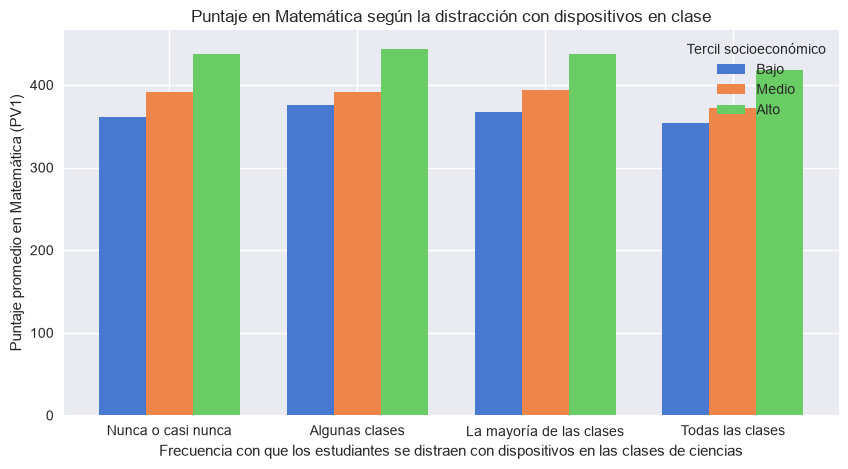

In [45]:
posiciones = np.arange(len(orden_distraccion))
ancho = 0.25

plt.figure(figsize=(10, 5))
# Cada tercil se corre un ancho de barra a la derecha del anterior
for i, tercil in enumerate(orden_tercil):
    plt.bar(posiciones + i * ancho, promedios_pv1.loc[tercil], width=ancho, label=tercil)
plt.xticks(posiciones + ancho, orden_distraccion)
plt.title('Puntaje en Matemática según la distracción con dispositivos en clase')
plt.xlabel('Frecuencia con que los estudiantes se distraen con dispositivos en las clases de ciencias')
plt.ylabel('Puntaje promedio en Matemática (PV1)')
plt.legend(title='Tercil socioeconómico')
plt.show()

Las barras repiten la tabla de 4.5. Dentro de cada nivel de distracción, el tercil alto siempre supera al bajo (entre 64,3 y 76,3 puntos), y dentro de cada tercil el grupo con distracción en todas las clases es el más bajo: 354,0, 371,8 y 418,3 puntos. La distancia entre colores es mucho mayor que la que hay entre grupos de barras: el nivel socioeconómico se asocia con el puntaje bastante más que la distracción. El eje vertical empieza en 0, así que las diferencias de unos 20 puntos se ven chicas; los valores exactos están en 4.5.

### 5.2 Nivel socioeconómico y puntaje por escuela
Cada punto es una escuela: su índice socioeconómico promedio contra su puntaje promedio en Matemática. Con más de 10.000 estudiantes un gráfico por estudiante queda saturado; por escuela se lee mejor.

Escuelas: 405
Escuelas sin índice socioeconómico promedio: 0


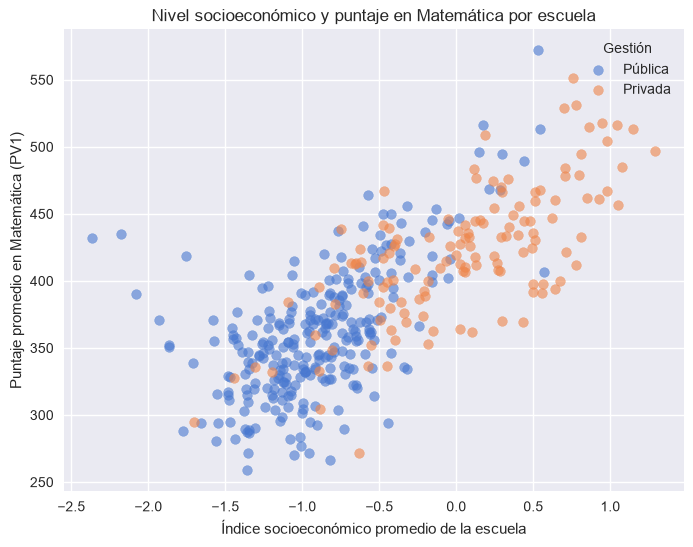

         indice_socioeconomico  pv1_matematica
gestion                                       
Privada                   0.04          420.75
Pública                  -0.90          360.93


In [46]:
por_escuela = estudiantes.groupby(['id_escuela', 'gestion'])[['indice_socioeconomico', 'pv1_matematica']].mean().reset_index()
print('Escuelas:', len(por_escuela))
print('Escuelas sin índice socioeconómico promedio:', por_escuela['indice_socioeconomico'].isna().sum())

plt.figure(figsize=(8, 6))
for tipo in ['Pública', 'Privada']:
    escuelas_tipo = por_escuela[por_escuela['gestion'] == tipo]
    plt.scatter(escuelas_tipo['indice_socioeconomico'], escuelas_tipo['pv1_matematica'], alpha=0.6, label=tipo)
plt.title('Nivel socioeconómico y puntaje en Matemática por escuela')
plt.xlabel('Índice socioeconómico promedio de la escuela')
plt.ylabel('Puntaje promedio en Matemática (PV1)')
plt.legend(title='Gestión')
plt.show()

print(por_escuela.groupby('gestion')[['indice_socioeconomico', 'pv1_matematica']].mean().round(2))

Hay 405 escuelas: las otras 7 quedaron sin estudiantes en la limpieza de 3.4. La nube sube de izquierda a derecha: las escuelas con mayor nivel socioeconómico promedio tienden a tener puntajes más altos. Las privadas se concentran arriba y a la derecha (índice promedio de 0,04 y 420,75 puntos) y las públicas abajo y a la izquierda (−0,90 y 360,93), aunque en la franja de índices entre −1 y 0 conviven escuelas de los dos tipos. Son promedios por escuela, en los que cada escuela cuenta igual sin importar cuántos estudiantes tiene, por eso no coinciden con los de 4.5 (0,07 y −0,83).

### 5.3 Con qué frecuencia se perciben distracciones en clase
Distribución de las respuestas a la pregunta sobre distracción con dispositivos. Tiene cuatro categorías, así que una torta se lee bien.

distraccion_categoria
Nunca o casi nunca          1841
Algunas clases              2573
La mayoría de las clases    2320
Todas las clases            2703
Name: count, dtype: int64


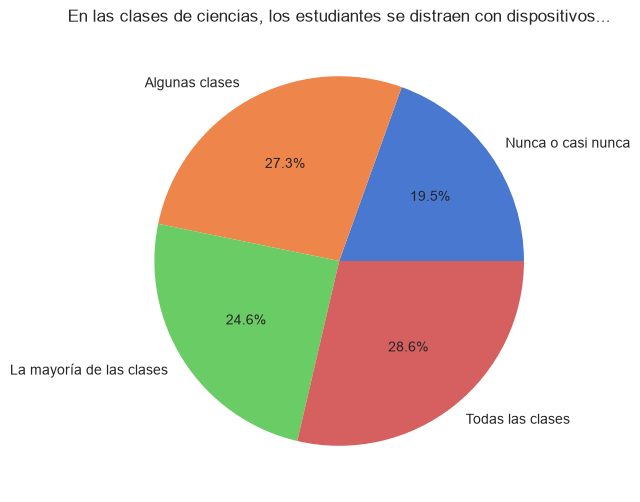

In [47]:
frecuencias = estudiantes['distraccion_categoria'].value_counts().loc[orden_distraccion]
print(frecuencias)

plt.figure(figsize=(6, 6))
plt.pie(frecuencias, labels=frecuencias.index, autopct='%1.1f%%')
plt.title('En las clases de ciencias, los estudiantes se distraen con dispositivos...')
plt.show()

De los 9.437 estudiantes que respondieron, el 28,6 % dice que en las clases de ciencias se distraen con dispositivos en todas las clases y el 24,6 % en la mayoría. Solo el 19,5 % responde que nunca o casi nunca pasa. Los porcentajes coinciden con los de 2.5, porque la limpieza de 3.4 no eliminó a nadie que hubiera respondido esta pregunta.

## 6. Conclusiones

*(Pendiente: respuesta a las preguntas guía, reflexión y limitaciones.)*

## Anexo: técnicas utilizadas y dónde se vieron en clase
Relevado contra los notebooks y presentaciones de la cursada (carpeta `materiales/`).

| Técnica | Uso en este notebook | Dónde se vio |
|---|---|---|
| `pd.read_csv` | Carga de los tres CSV | Clase 6, 7, 8 y Final |
| `.shape`, `.head()`, `.info()`, `.describe()` | Exploración inicial y dataset final | Clase 6 (también 5, 7 y 8) |
| `.value_counts()`, `normalize=True` | Frecuencias | Clase 6 y 8 |
| `.mul()`, `.round()` | Porcentajes y redondeo | Clase 8 |
| `.loc[...]` (selección y asignación con máscara) | Columnas indicadoras, terciles, filtros | Clase 7 y 8 |
| `.loc` con lista de etiquetas | Ordenar filas y columnas según la escala | Clase 7 (allí, para elegir columnas) |
| `.iloc[...]` sobre una Serie | Cortes de los terciles | Clase 7 y Final; Clase 6 (diapositivas) |
| `.sort_values()` | Faltantes ordenados, cortes de terciles | Clase 6 (diapositivas) y 8 |
| `.unique()`, `.astype()` | Revisión de `pais`, `genero` a entero | Clase 8 |
| `.drop(columns=...)` | Columnas constantes o auxiliares | Clase 6 |
| `.drop_duplicates()` | Duplicados | Clase 8 |
| `.isna()`, `.notna()`, `.sum(axis=1)` | Faltantes y máscara de filas sin respuestas | Clase 8 |
| `~` (negar una máscara), `&` | Filtros booleanos | Clase 6 (diapositivas) y 8 |
| `.dropna(subset=...)` | Tablas de control | Clase 6 |
| `.fillna()` | "Sin dato" en variables de escuela | Clase 6 y 8 |
| `.map(dict)` | Categorías en texto | Clase 8; Clase 5 (diapositivas) |
| `.apply(lambda ...)` | Recodificación "más = más" | Clase 8; Clase 6 (diapositivas) |
| `.groupby()` + `.mean()`, `.size()`, `.agg([...])`, `.unstack()` | Comparaciones por grupo | Clase 8 |
| `.set_index()`, `.join()`, `.reset_index()` | Unión estudiantes-escuelas | Clase 8 (`join`), Final (`set_index`, `reset_index`) |
| `.tolist()` | Listas de columnas y conteos | Clase 8 |
| `np.nan` | Reemplazo del código 6 | Clase 8 |
| `for`, diccionarios, f-strings, `//`, `len`, `round` | Renombrado, ciclos, cortes | Clase 1, 3 y 5 |
| `.rename(columns=...)` | Nombres descriptivos | Consigna (también Clase 6, diapositivas) |
| `.duplicated()` | Duplicados | Consigna (también Clase 4, diapositivas) |
| `pd.cut(bins=..., labels=...)` | Rangos de horas de ocio | Clase 8 |
| `.isin()` | Escuelas que quedan sin estudiantes | Clase 6 (diapositivas) |
| `np.arange` | Posiciones de las barras agrupadas | Clase 5 (diapositivas) |
| `enumerate` | Ciclo por tercil en el gráfico de barras | Clase 1 y 8 |
| `plt.figure`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.show` | Todos los gráficos | Clase Final |
| `plt.xticks(posiciones, etiquetas)` | Etiquetas de las barras agrupadas | Parámetros de `plt.xticks`, visto en la Clase Final (allí solo con `rotation`) |
| `plt.bar` | Gráfico 5.1 | Consigna |
| `width` de `plt.bar` | Ancho de las barras agrupadas | Parámetro de `plt.bar` (consigna); `plt.bar` no aparece en `materiales/` |
| `plt.scatter`, `alpha` | Gráfico 5.2 | Consigna (`alpha`, Clase Final con `sns.scatterplot`) |
| `plt.pie`, `autopct` | Gráfico 5.3 | Consigna (`autopct`, Clase Final con `.plot(kind='pie')`) |
| `plt.legend()` | Gráficos 5.1 y 5.2 | Consigna (leyendas legibles) |
| `pyreadstat` | Solo en `preparar_datos.py`, para leer los `.sav` | Excepción aprobada |